Assignment 6: Heart Disease Dataset

In this assignment, i will load, perform exploratory data analysis (EDA), handle missing values, deal with outliers, encode categorical variables, perform feature scaling, and prepare the data for modeling.

Load the Dataset and Split the Data

In [2]:
%pip install pandas 

  Using cached tzdata-2026.5-py2.py3-none-any.whl.metadata (1.4 kB)
   ---------------------------------------- 0.0/10.9 MB ? eta -:--:--
   ---------- ----------------------------- 2.9/10.9 MB 19.2 MB/s eta 0:00:01
   -------------------------- ------------- 7.3/10.9 MB 20.0 MB/s eta 0:00:01
   ---------------------------------------  10.7/10.9 MB 20.2 MB/s eta 0:00:01
   ---------------------------------------- 10.9/10.9 MB 18.8 MB/s  0:00:00
Using cached tzdata-2026.5-py2.py3-none-any.whl (347 kB)

   ---------------------------------------- 0/2 [tzdata]
   ---------------------------------------- 0/2 [tzdata]
   -------------------- ------------------- 1/2 [pandas]
   -------------------- ------------------- 1/2 [pandas]
   -------------------- ------------------- 1/2 [pandas]
   -------------------- ------------------- 1/2 [pandas]
   -------------------- ------------------- 1/2 [pandas]
   -------------------- ------------------- 1/2 [pandas]
   -------------------- -------------


[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split

columns = [
    'age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
    'exang', 'oldpeak', 'slope', 'ca', 'thal', 'num'
]
categorical_cols = ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']
continuous_cols = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']

# The Cleveland file is headerless; '?' marks missing values.
df = pd.read_csv(
    'heart+disease/processed.cleveland.data',
    header=None,
    names=columns,
    na_values='?'
)

# Predict the diagnosis (0 = no disease; 1-4 = disease severity).
X = df.drop(columns='num')
y = df['num']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

print(f'Dataset shape: {df.shape}')
print(X_train.head())

Dataset shape: (303, 14)
      age  sex   cp  trestbps   chol  fbs  restecg  thalach  exang  oldpeak  \
199  59.0  1.0  1.0     160.0  273.0  0.0      2.0    125.0    0.0      0.0   
164  48.0  1.0  3.0     124.0  255.0  1.0      0.0    175.0    0.0      0.0   
96   59.0  1.0  4.0     110.0  239.0  0.0      2.0    142.0    1.0      1.2   
30   69.0  0.0  1.0     140.0  239.0  0.0      0.0    151.0    0.0      1.8   
202  57.0  1.0  3.0     150.0  126.0  1.0      0.0    173.0    0.0      0.2   

     slope   ca  thal  
199    1.0  0.0   3.0  
164    1.0  2.0   3.0  
96     2.0  1.0   7.0  
30     1.0  2.0   3.0  
202    1.0  1.0   7.0  


Perform Exploratory Data Analysis (EDA)

In [2]:
# Summary statistics for training data
print(X_train.describe())

# Check for missing data
print(X_train.isnull().sum())

              age         sex          cp    trestbps        chol         fbs  \
count  212.000000  212.000000  212.000000  212.000000  212.000000  212.000000   
mean    54.448113    0.679245    3.160377  131.655660  248.783019    0.155660   
std      9.190565    0.467871    0.940271   17.567185   54.953838    0.363391   
min     34.000000    0.000000    1.000000   94.000000  126.000000    0.000000   
25%     47.750000    0.000000    2.750000  120.000000  211.000000    0.000000   
50%     55.000000    1.000000    3.000000  130.000000  245.000000    0.000000   
75%     61.250000    1.000000    4.000000  140.000000  277.250000    0.000000   
max     77.000000    1.000000    4.000000  200.000000  564.000000    1.000000   

          restecg     thalach       exang     oldpeak       slope          ca  \
count  212.000000  212.000000  212.000000  212.000000  212.000000  211.000000   
mean     1.009434  150.268868    0.330189    1.040094    1.589623    0.644550   
std      0.997583   22.1374

Handle Missing Data



In [3]:
# Impute missing predictor values with medians computed from the training set.
imputation_values = X_train.median()
X_train = X_train.fillna(imputation_values)

# Verify that missing values were handled.
print(X_train.isnull().sum())

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
dtype: int64


Dealing with Outliers

In [5]:
%pip install seaborn

  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
  Using cached matplotlib-3.11.2-cp314-cp314-win_amd64.whl.metadata (80 kB)
  Using cached contourpy-1.4.0-cp314-cp314-win_amd64.whl.metadata (3.8 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached kiwisolver-1.5.1-cp314-cp314-win_amd64.whl.metadata (5.2 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)
Using cached matplotlib-3.11.2-cp314-cp314-win_amd64.whl (9.5 MB)
Using cached contourpy-1.4.0-cp314-cp314-win_amd64.whl (240 kB)
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
   ---------------------------------------- 2.5/2.5 MB 16.3 MB/s  0:00:00
Using cached kiwisolver-1.5.1-cp314-cp314-win_amd64.whl (72 kB)
   ---------------------------------------- 0.0/7.3 MB ? eta -:--:--
   ------------------------ --------------- 4.5/7.3 MB 20.4 MB/s 


[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


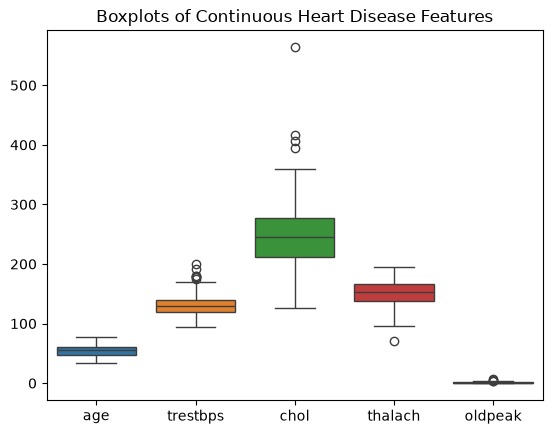

In [4]:
import seaborn as sns
import matplotlib.pyplot as plt


# Plot continuous features to inspect outliers.
sns.boxplot(data=X_train[continuous_cols])
plt.title('Boxplots of Continuous Heart Disease Features')
plt.show()

# Cap continuous feature outliers at training-set 95th percentiles.
cap = X_train[continuous_cols].quantile(0.95)
X_train[continuous_cols] = X_train[continuous_cols].clip(upper=cap, axis=1)

Handling Categorical Variables

In [5]:
# One-hot encode categorical features.
X_train = pd.get_dummies(X_train, columns=categorical_cols, drop_first=True)
feature_columns = X_train.columns

# Display first few rows to verify encoding.
print(X_train.head())

      age  trestbps   chol  thalach  oldpeak  sex_1.0  cp_2.0  cp_3.0  cp_4.0  \
199  59.0     160.0  273.0    125.0      0.0     True   False   False   False   
164  48.0     124.0  255.0    175.0      0.0     True   False    True   False   
96   59.0     110.0  239.0    142.0      1.2     True   False   False    True   
30   68.0     140.0  239.0    151.0      1.8    False   False   False   False   
202  57.0     150.0  126.0    173.0      0.2     True   False    True   False   

     fbs_1.0  restecg_1.0  restecg_2.0  exang_1.0  slope_2.0  slope_3.0  \
199    False        False         True      False      False      False   
164     True        False        False      False      False      False   
96     False        False         True       True       True      False   
30     False        False        False      False      False      False   
202     True        False        False      False      False      False   

     ca_1.0  ca_2.0  ca_3.0  thal_6.0  thal_7.0  
199   False 

Feature Scaling

In [6]:
from sklearn.preprocessing import StandardScaler

# Standardize continuous features using training-set statistics.
scaler = StandardScaler()
X_train[continuous_cols] = scaler.fit_transform(X_train[continuous_cols])

# Preview scaled features
print(X_train[continuous_cols].head())

          age  trestbps      chol   thalach   oldpeak
199  0.530782  1.905811  0.567344 -1.154127 -0.945948
164 -0.708241 -0.441695  0.186134  1.152408 -0.945948
96   0.530782 -1.354615 -0.152719 -0.369905  0.190798
30   1.544529  0.601641 -0.152719  0.045271  0.759172
202  0.305505  1.253726 -2.545869  1.060147 -0.756491


Preparing the Test Data

In [7]:
# Apply training-set imputation values to the test set.
X_test = X_test.fillna(imputation_values)

# Apply the training-set outlier caps.
X_test[continuous_cols] = X_test[continuous_cols].clip(upper=cap, axis=1)

# Match the training feature columns after one-hot encoding.
X_test = pd.get_dummies(X_test, columns=categorical_cols, drop_first=True)
X_test = X_test.reindex(columns=feature_columns, fill_value=0)

# Apply the scaler fitted on the training set.
X_test[continuous_cols] = scaler.transform(X_test[continuous_cols])

# Preview preprocessed test data
print(X_test.head())

          age  trestbps      chol   thalach   oldpeak  sex_1.0  cp_2.0  \
201  1.093975  1.905811  1.668617  0.183663 -0.945948    False   False   
34  -1.158795 -0.050444 -0.279789  1.336931 -0.567033     True   False   
60  -0.370326 -0.050444  1.245051 -0.369905  0.190798    False   False   
246  0.418144 -2.006700 -0.258610  0.275925 -0.851219     True   False   
163  0.418144 -2.006700  0.037886 -1.292520  0.001341    False   False   

     cp_3.0  cp_4.0  fbs_1.0  restecg_1.0  restecg_2.0  exang_1.0  slope_2.0  \
201   False    True    False        False        False       True      False   
34     True   False    False        False        False       True      False   
60    False    True    False        False        False       True       True   
246   False    True    False        False        False      False      False   
163   False    True    False        False         True      False       True   

     slope_3.0  ca_1.0  ca_2.0  ca_3.0  thal_6.0  thal_7.0  
201      Fals